# Zenteno adaptado · recalibración con datos depurados y pulsos instantáneos
Química histórica X,N,G,F,E, sin transportadores ni aN/KNa. Ajuste químico exclusivamente LAB004–009 depurados; validación química LAB019–021. Gas: ajuste LAB019–021, holdout LAB016–018, sin seleccionar parámetros con el holdout.
YAN ≤20 mg/L a cero; exclusión estricta posterior al agotamiento+12 h; LAB006122h=0 y corte134h. Sin corte de biomasa tardía ni pulso inicial extra. SigmaX=max(.50g/L,3 sigma de réplicas de entrenamiento). Nutrición mediante saltos instantáneos de N, conservando dosis y horarios. Si una muestra coincide con el evento, se evalúa antes del salto; la dosis completa se incorpora inmediatamente después.
Ocho parámetros químicos libres; Kd0 fijo a0.00044h^-1 según Zenteno; Kn fijo a0.01g/L a23C según tabla2 de Zenteno, homologado al Kn0 del código a20C; cinco parámetros adicionales fijos desde theta_full; rendimientos≤.5114. Dos inicios, mismos límites del03; sin escenarios adicionales de parámetros libres/fijos. La dinámica histórica conserva mortalidad y mantenimiento; no se fuerza N a cero por debajo de20mg/L: esa regla trata observaciones.
CO₂: qprod=[mu/12.72+(betaG+betaF)/1.05]X; acumulación=min(qprod,kLa max(Csat-Cd,0)), gas=producción-acumulación. Csat1.5g/L y Cd0=0; sin tolerancia artificial de saturación. Se ajustan kLa y ganancia propios. Esta es una adaptación, no reproducción literal de todo el paper. Medianas horarias RAW, MSE ordinario con igual peso porLAB, sin filtrar predicciones. Ganancia fuera del balance físico.
Todos los resultados y parámetros quedan dentro del EXECUTED; no se sobrescriben datos, módulos ni configuraciones.

Política numérica compartida con los modelos del repositorio: mínimos internos G/F hasta −1e-4g/L y otros estados hasta −1e-6g/L; candidatos fuera de tolerancia rechazados. Se registran mínimos y sólo se proyectan a cero las salidas negativas admitidas, sin alterar el RHS.

Frontera física explícita (igual que modelos nuevos del repositorio): al agotarse G o F se anula el crecimiento y sus consumos asociados, ya que ambos balances requieren azúcar para crecer. La fermentación del azúcar restante y la mortalidad continúan. No se añade parámetro ni factor suave; esta adaptación evita consumir un sustrato ausente y se aplica tanto al ajuste como a todas las evaluaciones y la fuente de CO₂.

Esta revisión reemplaza la ejecución anterior en el mismo notebook: no se compara Kn libre/fijo. Kn(T) conserva la ley térmica; se verifica Kn(23C)=0.01g/L y Kd0=0.00044h^-1 durante todo el ajuste. Se conserva el umbral de mortalidad y su ley térmica y de etanol. La tabla2 etiqueta23C, mientras el código usa20C como referencia; la conversión se hace explícita, sin estimar otra dependencia térmica.


In [1]:
from pathlib import Path
from dataclasses import replace
import sys,json,hashlib,math,time
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares,minimize_scalar
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/wine_fermentation').is_dir())
assert Path(sys.prefix).name.lower()=='fermentation'
sys.path.insert(0,str(ROOT/'src'));sys.dont_write_bytecode=True
from wine_fermentation import model as kin
from wine_fermentation.data import natural_batches
from wine_fermentation.models.historical.calibration import load
from wine_fermentation.comparison import observations,chemical_observations,CHEMICAL_COLUMNS
NAME='16_zenteno_recalibration_legacy_treatment'
protected=[p for folder in ['src','configs','data/compatibility/chemistry','data/cleaned/natural/lab004_009','notebooks'] for p in (ROOT/folder).rglob('*') if p.is_file() and '__pycache__' not in str(p) and not p.name.startswith(NAME+'.')]
hashes={p:hashlib.sha256(p.read_bytes()).hexdigest() for p in protected}
data,training,profiles=natural_batches(ROOT)
start=kin.normalize_parameters(json.loads((ROOT/'configs/theta/theta_full.json').read_text()))
config=json.loads((ROOT/'configs/models/without_transporters/calibration.json').read_text())
# Tabla 2 de Zenteno: Kn=0.01 g/L a23C; nuestro Kn0 se referencia a20C.
KN_ZENTENO_G_L=0.01;KN_PAPER_REF_K=296.15;KN_CODE_REF_K=293.15
KN_THERMAL_FACTOR=np.exp(kin.FIXED_CONSTANTS['EaKn']*(KN_PAPER_REF_K-KN_CODE_REF_K)/(KN_CODE_REF_K*kin.FIXED_CONSTANTS['R']*KN_PAPER_REF_K))
start['Kn0']=KN_ZENTENO_G_L/KN_THERMAL_FACTOR
KD0_ZENTENO_H=0.00044
start['Kd0']=KD0_ZENTENO_H
assert np.isclose(start['Kn0']*KN_THERMAL_FACTOR,KN_ZENTENO_G_L,rtol=1e-14)
display(pd.Series(dict(Kn_Zenteno_g_L=KN_ZENTENO_G_L,referencia_paper_C=23,Kn0_codigo_g_L=start['Kn0'],referencia_codigo_C=20),name='Kn fijo y conversión de referencia térmica'))
names=[k for k in config['bounds'] if k not in ['aN','KNa','Kn0','Kd0']]
assert len(names)==8 and 'Kn0' not in names and 'Kd0' not in names
bounds={k:config['bounds'][k] for k in names};lo,hi=np.array(list(bounds.values())).T
fixed={k:v for k,v in start.items() if k not in names}
display(pd.Series(fixed,name='Fijos: theta_full salvo Kn y Kd0 de Zenteno'))
display(pd.DataFrame([dict(parametro=k,inicio=start[k],inicio_factible=np.clip(start[k],lo[i]+1e-10,hi[i]-1e-10),minimo=lo[i],maximo=hi[i]) for i,k in enumerate(names)]))


Kn_Zenteno_g_L          0.010000
referencia_paper_C     23.000000
Kn0_codigo_g_L          0.008258
referencia_codigo_C    20.000000
Name: Kn fijo y conversión de referencia térmica, dtype: float64

Kn0     0.008258
Kg0     4.400775
Kf0    19.296084
Kd0     0.000440
Yxg     0.966094
Yxf     1.109896
m0      0.018339
Name: Fijos: theta_full salvo Kn y Kd0 de Zenteno, dtype: float64

,parametro,inicio,inicio_factible,minimo,maximo
0,mu0,0.078728,0.078728,0.05,1.0000
1,betaG0,0.428878,0.428878,0.10,10.0000
2,betaF0,3.440399,3.440399,0.10,10.0000
3,Kig0,17.845213,17.845213,5.00,1000.0000
4,Kie0,24.895476,24.895476,5.00,1000.0000
5,Yxn,3.734653,3.734653,1.00,100.0000
6,Yeg,0.250395,0.250395,0.10,0.5114
7,Yef,0.684927,0.511400,0.10,0.5114


## Auditoría de observaciones y ponderación
Sólo se modifican en memoria los objetivos de YAN. Las figuras separan muestras originales, utilizadas y excluidas. Los huecos siguen ausentes. Las iniciales son entradas y no puntúan. Las réplicas para estimar sigmaX son004/005 y007/008 a tiempos coincidentes; no se emplean datos de validación.


In [2]:
diffs=[]
bylab={b.batch:b for b in training}
for a,b in [('LAB004','LAB005'),('LAB007','LAB008')]:
 aa=pd.Series(bylab[a].observations['X'],index=bylab[a].time);bb=pd.Series(bylab[b].observations['X'],index=bylab[b].time)
 z=pd.concat([aa,bb],axis=1).dropna();diffs.extend((z.iloc[:,0]-z.iloc[:,1]).tolist())
sigma_rep=float(np.sqrt(np.mean(np.square(diffs)))/np.sqrt(2));SIGMA_X=max(.5,3*sigma_rep)
assert len(diffs)>0
print('Pares de réplicas:',len(diffs),'sigma réplica:',sigma_rep,'sigmaX aplicada:',SIGMA_X)
treated=[];audit=[];rules=[]
for b in training:
 obs={k:v.copy() for k,v in b.observations.items()};old=obs['N'].copy()
 obs['N'][np.isfinite(old)&(old<=.020)]=0
 if b.batch=='LAB006':
  ids=np.flatnonzero(np.isclose(b.time,122)&np.isfinite(old));assert len(ids)==1 and np.isclose(old[ids[0]],.027)
  obs['N'][ids]=0;depletion=122.
 else:
  last=max(t for t,d in b.pulses['N']);ids=np.flatnonzero((b.time>=last)&np.isfinite(obs['N'])&(obs['N']==0));assert len(ids)
  depletion=float(b.time[ids[0]])
 obs['N'][b.time>depletion+12]=np.nan
 for i in np.flatnonzero(np.isfinite(old)):
  audit.append(dict(LAB=b.batch,t_h=b.time[i],original_mg=old[i]*1000,usado_mg=obs['N'][i]*1000,estado='Inicial' if b.time[i]==0 else ('Excluido' if not np.isfinite(obs['N'][i]) else ('Transformado' if old[i]!=obs['N'][i] else 'Usado'))))
 assert all(np.array_equal(obs[k],b.observations[k],equal_nan=True) for k in obs if k!='N')
 treated.append(replace(b,observations=obs))
 rules.append(dict(LAB=b.batch,agotamiento_h=depletion,corte_YAN_h=depletion+12,N0_mg=b.initials['N']*1000,pulsos=b.pulses['N'],**{k:int(np.count_nonzero(np.isfinite(obs[k])&(b.time>0))) for k in obs}))
audit=pd.DataFrame(audit);display(pd.DataFrame(rules));display(audit)
def sigma(state,y):return np.full_like(y,SIGMA_X) if state=='X' else kin.sigma_for_state(state,y)
def simulate(b,p):
 def rhs(t,y):
  out=np.asarray(kin.rhs(t,y,p,b))
  if y[2]<=0 or y[3]<=0:
   q=kin.kinetic_terms(p,kin.temperature_at(b,t),*y);growth=q['mu']*max(float(y[0]),0)
   out[0]-=growth;out[1]+=growth/p['Yxn'];out[2]+=growth/p['Yxg'];out[3]+=growth/p['Yxf']
  return out
 # Muestra previa al salto si coincide con la nutrición; dosis completa después.
 minimum=np.full(5,np.inf);jumps=[];events={}
 for tp,dose in b.pulses.get('N',()):
  assert tp>float(b.time[0]) and dose>=0,'No se admiten pulsos iniciales extra'
  if tp<=b.time[-1]:events[float(tp)]=events.get(float(tp),0.)+float(dose)
 times=np.asarray(b.time);state=kin.initial_vector(b);records={float(times[0]):state.copy()};now=float(times[0])
 for end in sorted(set([float(times[-1])]+list(events))):
  requested=times[(times>now)&(times<=end)]
  sol=solve_ivp(rhs,(now,end),state,t_eval=np.unique(np.r_[requested,end]),method='LSODA',rtol=2e-6,atol=2e-8,max_step=.5)
  if not sol.success or not np.isfinite(sol.y).all() or np.any(sol.y.min(axis=1)<-np.array([1e-6,1e-6,1e-4,1e-4,1e-6])):raise RuntimeError('Integración química inválida '+b.batch+' '+str(sol.message)+' mínimos='+str(dict(zip(kin.STATE_NAMES,sol.y.min(axis=1)))))
  minimum=np.minimum(minimum,sol.y.min(axis=1))
  records.update({float(t):y.copy() for t,y in zip(sol.t,sol.y.T)});state=sol.y[:,-1].copy();now=end
  if end in events:
   before=state.copy();state[1]+=events[end]
   assert np.isclose(state[1]-before[1],events[end],atol=1e-12) and np.array_equal(state[[0,2,3,4]],before[[0,2,3,4]])
   jumps.append(dict(t=end,dose=events[end],before=before.copy(),after=state.copy()))
 f=pd.DataFrame(np.maximum(np.vstack([records[float(t)] for t in times]),0),index=times,columns=kin.STATE_NAMES);f['GF']=f.G+f.F
 f.attrs['minimum_integrated_states']=dict(zip(kin.STATE_NAMES,minimum.tolist()))
 f.attrs['pulse_jumps']=jumps
 assert np.isclose(sum(j['dose'] for j in jumps),sum(events.values()),atol=1e-12)
 return f

def with_jumps(f):
 extra=[];tt=[]
 for j in f.attrs['pulse_jumps']:
  if j['t'] not in f.index:extra.append(j['before']);tt.append(j['t'])
  extra.append(j['after']);tt.append(j['t'])
 if not extra:return f
 added=pd.DataFrame(extra,index=tt,columns=kin.STATE_NAMES);added['GF']=added.G+added.F
 return pd.concat([f,added]).sort_index(kind='stable')

support=[(b,s,np.isfinite(b.observations[s])&(b.time>0)) for b in treated for s in kin.STATE_NAMES]
NR=sum(m.sum() for b,s,m in support);calls=0;rejected=0


Pares de réplicas: 23 sigma réplica: 0.11981151229435705 sigmaX aplicada: 0.5


,LAB,agotamiento_h,corte_YAN_h,N0_mg,pulsos,X,N,G,F,E
0,LAB004,91.0,103.0,230.76,"((68.5, 0.08),)",10,8,12,12,4
1,LAB005,91.0,103.0,227.30,"((68.5, 0.08),)",10,8,12,12,4
2,LAB006,122.0,134.0,229.12,"((100.0, 0.08),)",12,9,14,14,4
3,LAB007,88.0,100.0,239.04,"((65.5, 0.08),)",11,8,12,12,5
4,LAB008,88.0,100.0,239.22,"((65.5, 0.08),)",11,8,12,12,5
5,LAB009,64.0,76.0,237.40,"((41.84615384615385, 0.08),)",10,6,11,11,4


,LAB,t_h,original_mg,usado_mg,estado
0,LAB004,0.0,230.76,230.76,Inicial
1,LAB004,19.0,182.72,182.72,Usado
2,LAB004,26.0,157.42,157.42,Usado
3,LAB004,43.0,60.16,60.16,Usado
4,LAB004,50.0,19.00,0.00,Transformado
...,...,...,...,...,...
74,LAB009,88.0,17.00,NaN,Excluido
75,LAB009,96.0,19.00,NaN,Excluido
76,LAB009,120.0,5.00,NaN,Excluido
77,LAB009,144.0,25.00,NaN,Excluido


## Recalibración química · sólo LAB004–009
Los parámetros se optimizan en logaritmos. El segundo inicio es una perturbación del mismo theta_full; selección únicamente por objetivo químico de entrenamiento. Se reportan convergencia, parámetros en cota y sensibilidad local; no se afirma óptimo global.


In [3]:
def residual(logp):
 global calls,rejected
 calls+=1;p={**start,**dict(zip(names,np.exp(logp)))}
 try:pred={b.batch:simulate(b,p) for b in treated}
 except (RuntimeError,ValueError,FloatingPointError):
  rejected+=1;return np.full(NR,1e4)
 e=np.concatenate([(pred[b.batch][s].to_numpy()[m]-b.observations[s][m])/sigma(s,b.observations[s][m]) for b,s,m in support])
 if calls%50==0:print('Evaluaciones',calls,'MSE',float(np.mean(e*e)),'rechazos',rejected,flush=True)
 return e
rng=np.random.default_rng(20261101);x0=np.array([start[k] for k in names]);seeds=[x0,x0*np.exp(rng.normal(0,.2,len(names)))];runs=[];runrows=[]
for j,seed in enumerate(seeds):
 sol=least_squares(residual,np.log(np.clip(seed,lo+1e-10,hi-1e-10)),bounds=(np.log(lo),np.log(hi)),max_nfev=100,diff_step=1e-3,ftol=2e-5,xtol=2e-5,gtol=2e-5)
 runs.append(sol);runrows.append(dict(inicio=j,success=sol.success,nfev=sol.nfev,MSE=float(np.mean(sol.fun**2)),message=sol.message));print(runrows[-1],flush=True)
best=min(runs,key=lambda s:s.fun@s.fun);theta={**start,**dict(zip(names,np.exp(best.x)))}
assert theta['Kd0']==KD0_ZENTENO_H and 'Kd0' not in names
assert theta['Kn0']==start['Kn0'] and np.isclose(theta['Kn0']*KN_THERMAL_FACTOR,.01,rtol=1e-14)
assert theta['Yeg']<=.5114 and theta['Yef']<=.5114 and all(theta[k]==v for k,v in fixed.items())
display(pd.DataFrame(runrows));display(pd.DataFrame([dict(parametro=k,valor=theta[k],minimo=lo[i],maximo=hi[i],cerca_cota=min(abs(np.log(theta[k]/lo[i])),abs(np.log(hi[i]/theta[k])))<.02) for i,k in enumerate(names)]))
print('PARÁMETROS QUÍMICOS COMPLETOS',json.dumps(theta,indent=2));print('Rechazos:',rejected,'Razón singular:',np.linalg.svd(best.jac,compute_uv=False)[-1]/np.linalg.svd(best.jac,compute_uv=False)[0])
traincurves={b.batch:simulate(b,theta) for b in treated}


Evaluaciones 50 MSE 4.0934917385398855 rechazos 0
Evaluaciones 100 MSE 4.045590102429652 rechazos 0
{'inicio': 0, 'success': True, 'nfev': 14, 'MSE': 4.045303513073513, 'message': '`ftol` termination condition is satisfied.'}
Evaluaciones 150 MSE 4.237360449937382 rechazos 0
Evaluaciones 200 MSE 4.069537530195936 rechazos 0
Evaluaciones 250 MSE 4.045392673816342 rechazos 0
{'inicio': 1, 'success': True, 'nfev': 18, 'MSE': 4.045371801542695, 'message': '`ftol` termination condition is satisfied.'}
PARÁMETROS QUÍMICOS COMPLETOS {
  "mu0": 0.0969183738471312,
  "betaG0": 0.37412078664376186,
  "betaF0": 0.4977264277329749,
  "Kn0": 0.008257860224319971,
  "Kg0": 4.400775419123265,
  "Kf0": 19.296083508118652,
  "Kig0": 73.67868243124637,
  "Kie0": 111.08000386629183,
  "Kd0": 0.00044,
  "Yxn": 7.080212929593885,
  "Yxg": 0.9660935553477866,
  "Yxf": 1.1098958529485594,
  "Yeg": 0.48208291645933304,
  "Yef": 0.5018143946925229,
  "m0": 0.0183385793928771
}
Rechazos: 0 Razón singular: 0.018

,inicio,success,nfev,MSE,message
0,0,True,14,4.045304,`ftol` termination condition is satisfied.
1,1,True,18,4.045372,`ftol` termination condition is satisfied.


,parametro,valor,minimo,maximo,cerca_cota
0,mu0,0.096918,0.05,1.0000,False
1,betaG0,0.374121,0.10,10.0000,False
2,betaF0,0.497726,0.10,10.0000,False
3,Kig0,73.678682,5.00,1000.0000,False
4,Kie0,111.080004,5.00,1000.0000,False
5,Yxn,7.080213,1.00,100.0000,False
6,Yeg,0.482083,0.10,0.5114,False
7,Yef,0.501814,0.10,0.5114,True


## Muestras de entrenamiento: originales, usadas y excluidas
Círculos negros: dato usado sin transformación; cuadrados verdes: YAN transformado a cero; cruces naranjas: dato excluido; círculos grises vacíos: valor original transformado. Iniciales azules vacías. La predicción se compara con el soporte realmente entregado al optimizador.


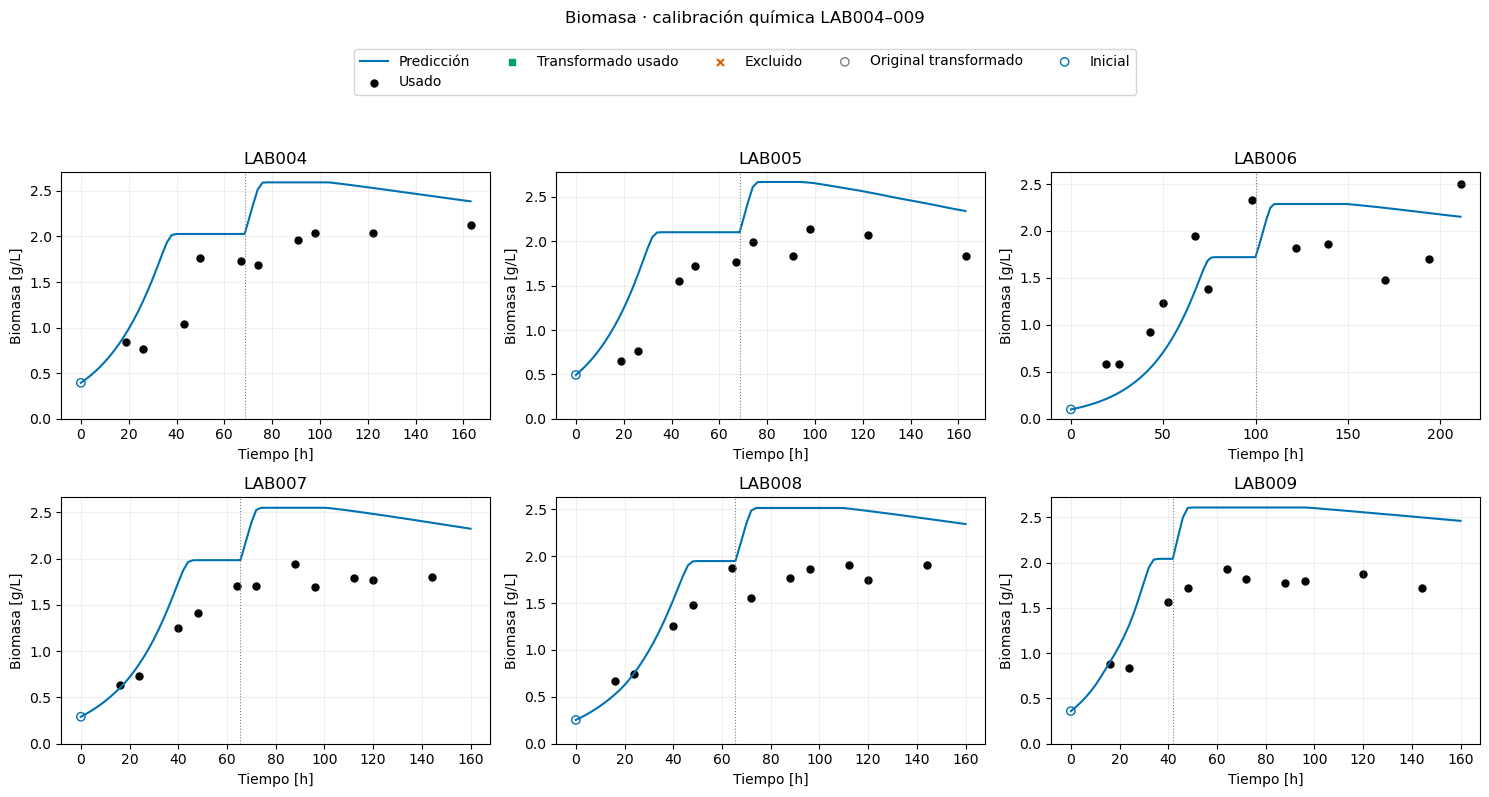

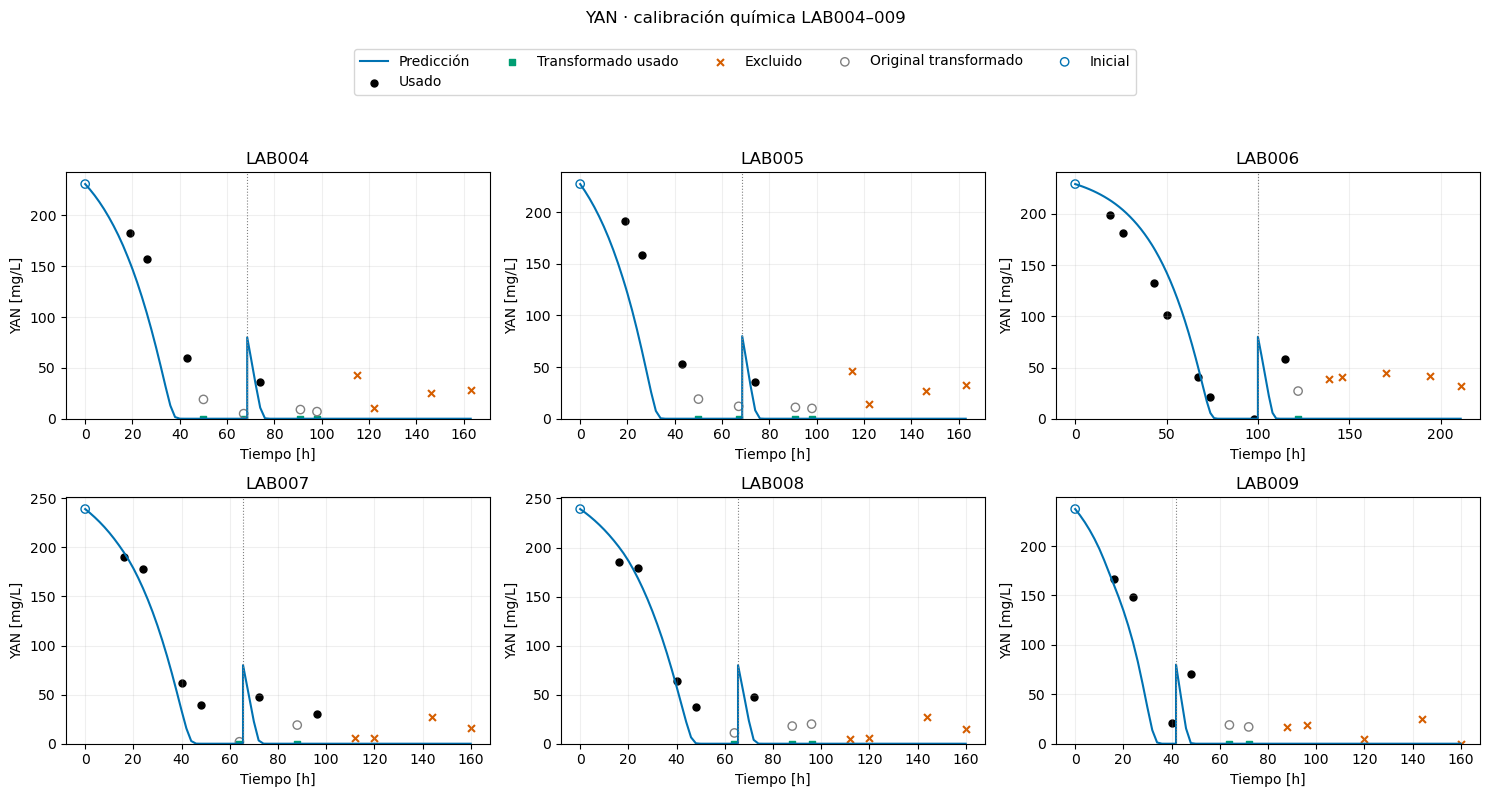

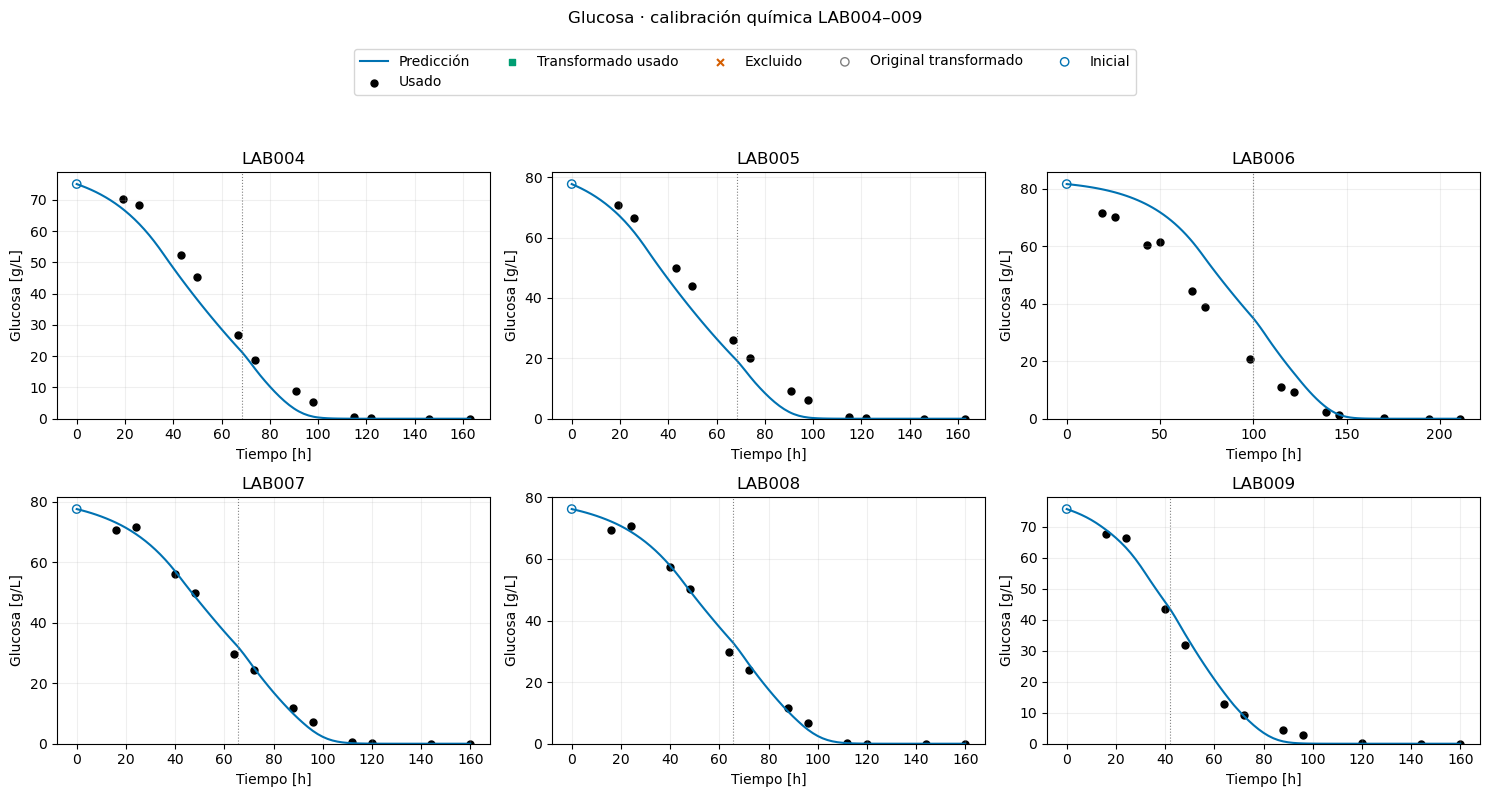

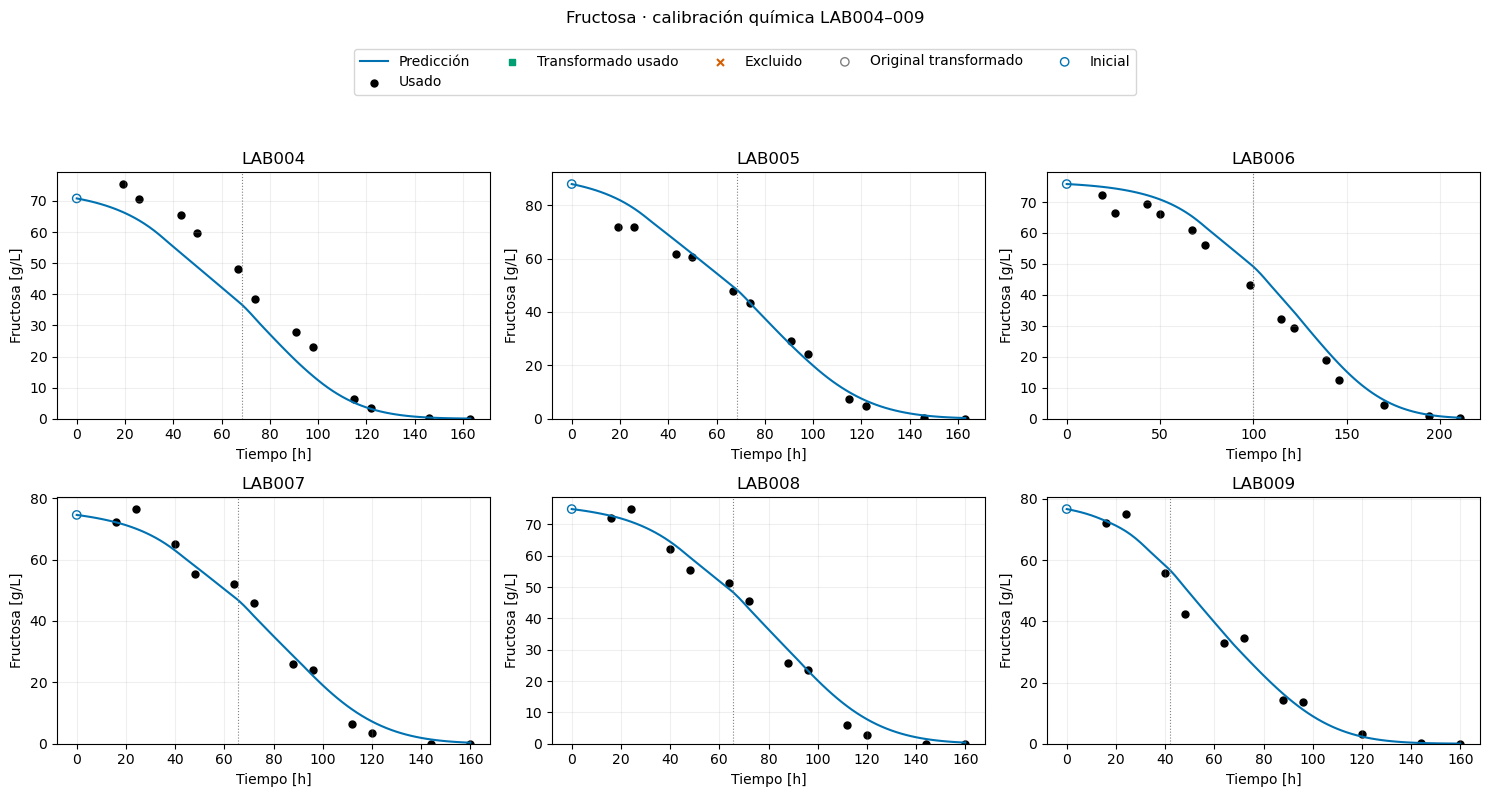

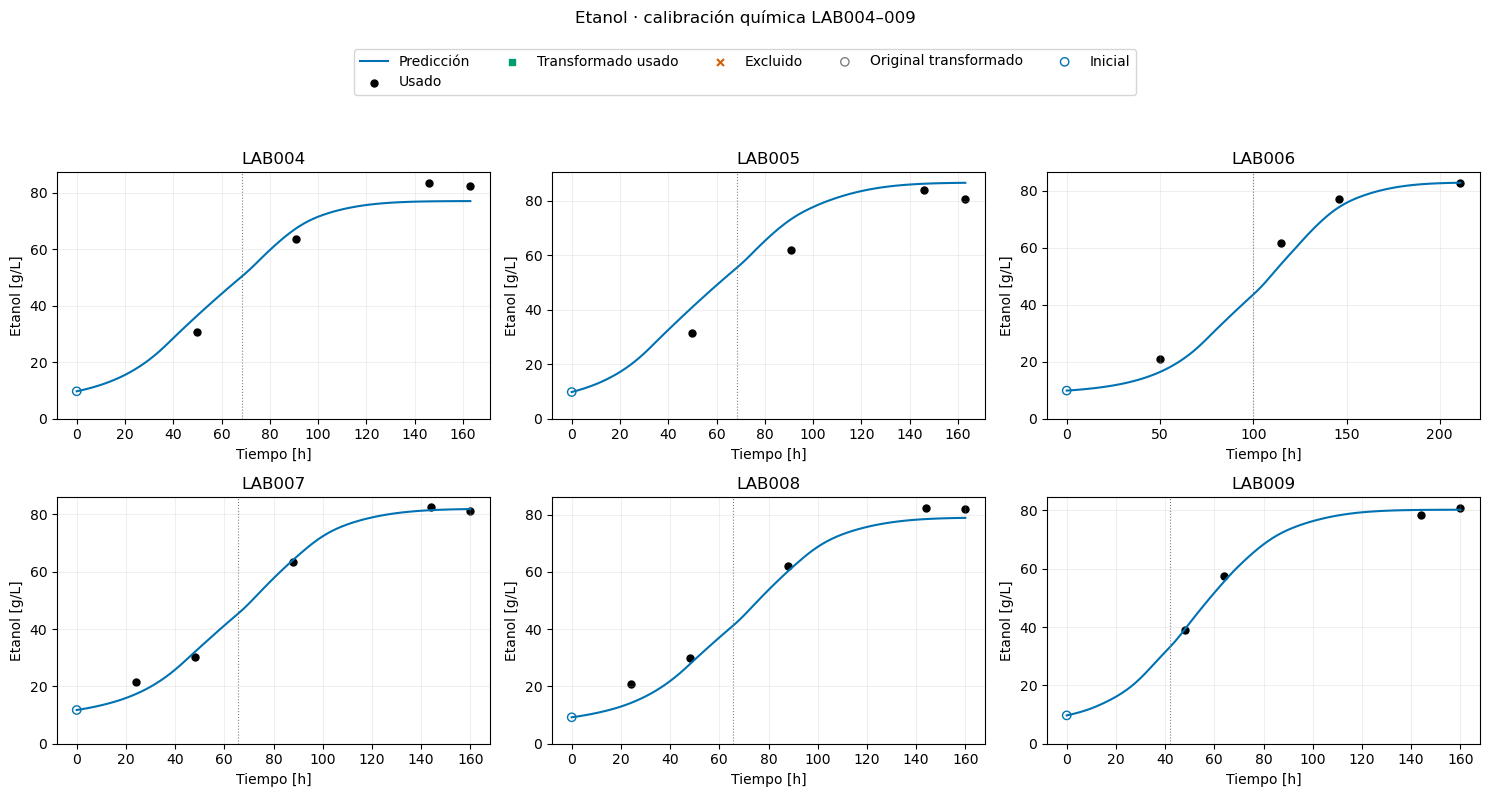

In [4]:
for s,title,scale in [('X','Biomasa',1),('N','YAN',1000),('G','Glucosa',1),('F','Fructosa',1),('E','Etanol',1)]:
 fig,axs=plt.subplots(2,3,figsize=(15,8));items={}
 for ax,b in zip(axs.flat,treated):
  old=bylab[b.batch].observations[s];new=b.observations[s];valid=np.isfinite(old)&(b.time>0);used=valid&np.isfinite(new);changed=used&(old!=new);excluded=valid&~np.isfinite(new)
  pf=with_jumps(traincurves[b.batch]);ax.plot(pf.index,pf[s]*scale,label='Predicción',c='#0072B2')
  for mask,val,marker,color,label in [(used&~changed,new,'o','black','Usado'),(changed,new,'s','#009E73','Transformado usado'),(excluded,old,'x','#D55E00','Excluido')]:ax.scatter(b.time[mask],val[mask]*scale,marker=marker,c=color,s=25,label=label)
  ax.scatter(b.time[changed],old[changed]*scale,facecolors='none',edgecolors='gray',label='Original transformado')
  ax.scatter([0],[b.initials[s]*scale],facecolors='none',edgecolors='#0072B2',label='Inicial')
  for t,d in b.pulses['N']:ax.axvline(t,c='gray',ls=':',lw=.8)
  ax.set(title=b.batch,xlabel='Tiempo [h]',ylabel=title+(' [mg/L]' if s=='N' else ' [g/L]'),ylim=(0,None));ax.grid(alpha=.2)
  for h,l in zip(*ax.get_legend_handles_labels()):items[l]=h
 fig.suptitle(title+' · calibración química LAB004–009',y=.99);fig.legend(items.values(),items.keys(),loc='upper center',bbox_to_anchor=(.5,.95),ncol=5);fig.tight_layout(rect=(0,0,1,.87));plt.show()


## Evaluación reservada y capa de CO₂
Entradas históricas: X0=.39g/L y E0=0 en016–018; iniciales medidas/derivadas del lector en019–021. LAB017 se consolida como un pulso nominal.28g/L.019–021: las masas nominales de nutrición se dividen por volumen remanente; no se agrega líquido. Los saltos instantáneos conservan la dosis corregida. No se usan los escenarios de dosis/volumen del15.
La señal de gas es RAW convertida por volumen remanente; Cs fijo1.5 y Cd0=0. No O2 ni gate ni multiplicador nutricional extra. Ganancia nueva, fuera del balance. Química019–021 es validación; esos LAB entrenan gas y no son holdout conjunto.


In [5]:
v=load(ROOT);LABS=['LAB019','LAB020','LAB021','LAB016','LAB017','LAB018'];TRAIN=LABS[:3];HOLD=LABS[3:]
raw=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',usecols=['lab','time_h','record_kind','remaining_volume_L','co2_raw_g_l_h']);obs=observations(raw)
batches={};cores={};volumes={};caches={};entry=[]
for lab in LABS:
 b=v.batches[lab];ev=raw.loc[raw.lab.eq(lab)&raw.record_kind.eq('withdrawal_after')].sort_values('time_h');et=ev.time_h.to_numpy();vv=ev.remaining_volume_L.to_numpy()
 def volume(t,et=et,vv=vv):return np.r_[2.,vv][np.searchsorted(et,np.asarray(t),side='right')]
 volumes[lab]=volume
 if lab in TRAIN:b=replace(b,pulses={**b.pulses,'N':tuple((t,d*2/float(volume(t))) for t,d in b.pulses['N'])})
 if lab=='LAB017':b=replace(b,pulses={**b.pulses,'N':((min(t for t,d in b.pulses['N']),sum(d for t,d in b.pulses['N'])),)})
 batches[lab]=b;f=simulate(b,theta);cores[lab]=f;f=with_jumps(f)
 tt=np.unique(np.r_[np.arange(0,float(f.index[-1]),.1),f.index[-1]])
 rates=[]
 for t in tt:
  y=[np.interp(t,f.index,f[s]) for s in kin.STATE_NAMES];q=kin.kinetic_terms(theta,kin.temperature_at(b,t),*y)
  if y[2]<=0 or y[3]<=0:q['mu']=0.
  rates.append((q['mu']/12.72+(q['beta_g']+q['beta_f'])/1.05)*y[0])
 caches[lab]=(tt,np.asarray(rates));entry.append(dict(LAB=lab,**b.initials,pulsos=b.pulses['N'],corte_h=v.horizons[lab]))
 obs[lab]=obs[lab].loc[obs[lab].time_h.between(0,v.horizons[lab])].copy()
display(pd.DataFrame(entry))
CSAT=1.5
def gas(lab,k,gain=1):
 t,source=caches[lab];cd=np.zeros(len(t));qout=np.zeros(len(t));acc=np.zeros(len(t));qout[0]=max(source[0]-k*CSAT,0)
 for i,dt in enumerate(np.diff(t),1):
  qp=(source[i-1]+source[i])/2;D=max(CSAT-cd[i-1],0)
  if qp<=0 or D<=0:delta=0.
  elif k*D<=qp:delta=D*(-np.expm1(-k*dt))
  else:
   crossing=(D-qp/k)/qp;linear=min(dt,crossing);delta=qp*linear
   if crossing<dt:delta+=(qp/k)*(-np.expm1(-k*(dt-crossing)))
  cd[i]=cd[i-1]+delta;acc[i]=delta/dt;qout[i]=qp-acc[i]
 assert cd.min()>=0 and cd.max()<=CSAT+1e-10 and qout.min()>-1e-10
 assert np.max(abs(np.diff(cd)-np.diff(t)*((source[:-1]+source[1:])/2-qout[1:])))<1e-10
 return pd.DataFrame(dict(qprod=source,Cd=cd,qgas=qout,qpred=gain*qout),index=t)
def gas_cost(logk,return_gain=False):
 k=np.exp(logk);numer=0.;denom=0.;pairs=[]
 for lab in TRAIN:
  f=gas(lab,k);o=obs[lab];y=o.co2_raw_g_l_h.to_numpy();z=np.interp(o.time_h,f.index,f.qgas)
  numer+=np.mean(z*y);denom+=np.mean(z*z);pairs.append((z,y))
 gain=float(np.clip(numer/max(denom,1e-20),.05,3.));cost=sum(np.mean((gain*z-y)**2) for z,y in pairs)
 return (cost,gain) if return_gain else cost
# Perfil y refinamiento: selección exclusivamente con los tres LAB de entrenamiento.
grid=np.linspace(np.log(1e-4),np.log(10),51);costs=[gas_cost(x) for x in grid];candidates=[(costs[0],grid[0]),(costs[-1],grid[-1])]
for i in range(1,len(grid)-1):
 if costs[i]<=costs[i-1] and costs[i]<=costs[i+1]:
  sol=minimize_scalar(gas_cost,bounds=(grid[i-1],grid[i+1]),method='bounded',options={'xatol':1e-6});candidates.append((sol.fun,sol.x))
value,logk=min(candidates);KLA=float(np.exp(logk));_,GAIN=gas_cost(logk,True)
print('PARÁMETROS GAS',json.dumps(dict(kLa=KLA,gain=GAIN,Csat=CSAT,Cd0=0,training=TRAIN,holdout=HOLD,objective=value),indent=2))
curves={lab:gas(lab,KLA,GAIN) for lab in LABS};metrics=[]
for lab in LABS:
 o=obs[lab];f=curves[lab];e=np.interp(o.time_h,f.index,f.qpred)-o.co2_raw_g_l_h
 metrics.append(dict(LAB=lab,rol='Calibración gas' if lab in TRAIN else 'Holdout gas',n=len(o),RMSE=np.sqrt(np.mean(e*e)),sesgo=np.mean(e)))
metrics=pd.DataFrame(metrics);display(metrics);display(metrics.groupby('rol')[['RMSE','sesgo']].mean())


PARÁMETROS GAS {
  "kLa": 0.11558424718334451,
  "gain": 0.6204348696214814,
  "Csat": 1.5,
  "Cd0": 0,
  "training": [
    "LAB019",
    "LAB020",
    "LAB021"
  ],
  "holdout": [
    "LAB016",
    "LAB017",
    "LAB018"
  ],
  "objective": 0.07726267811570416
}


,LAB,X,N,G,F,E,pulsos,corte_h
0,LAB019,0.283162,0.230025,79.190000,78.970000,12.075372,"((64.33333333333277, 0.08648648648648648),)",166.000000
1,LAB020,0.153342,0.225556,77.940000,79.520000,11.917524,"((71.66666666666694, 0.08888888888888889),)",172.333333
2,LAB021,0.136153,0.231202,80.190000,81.040000,11.759676,"((47.5, 0.08648648648648648),)",166.000000
3,LAB016,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93555555555583, 0.14),)",151.100000
4,LAB017,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.933611111110835, 0.28),)",141.000000
5,LAB018,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93166666666694, 0.14),)",141.000000


,LAB,rol,n,RMSE,sesgo
0,LAB019,Calibración gas,166,0.113234,0.013988
1,LAB020,Calibración gas,172,0.078037,0.032674
2,LAB021,Calibración gas,166,0.241559,0.017906
3,LAB016,Holdout gas,152,0.134877,0.000787
4,LAB017,Holdout gas,141,0.142017,-0.037494
5,LAB018,Holdout gas,141,0.131030,-0.012357


,RMSE,sesgo
rol,,
Calibración gas,0.144277,0.021523
Holdout gas,0.135975,-0.016355


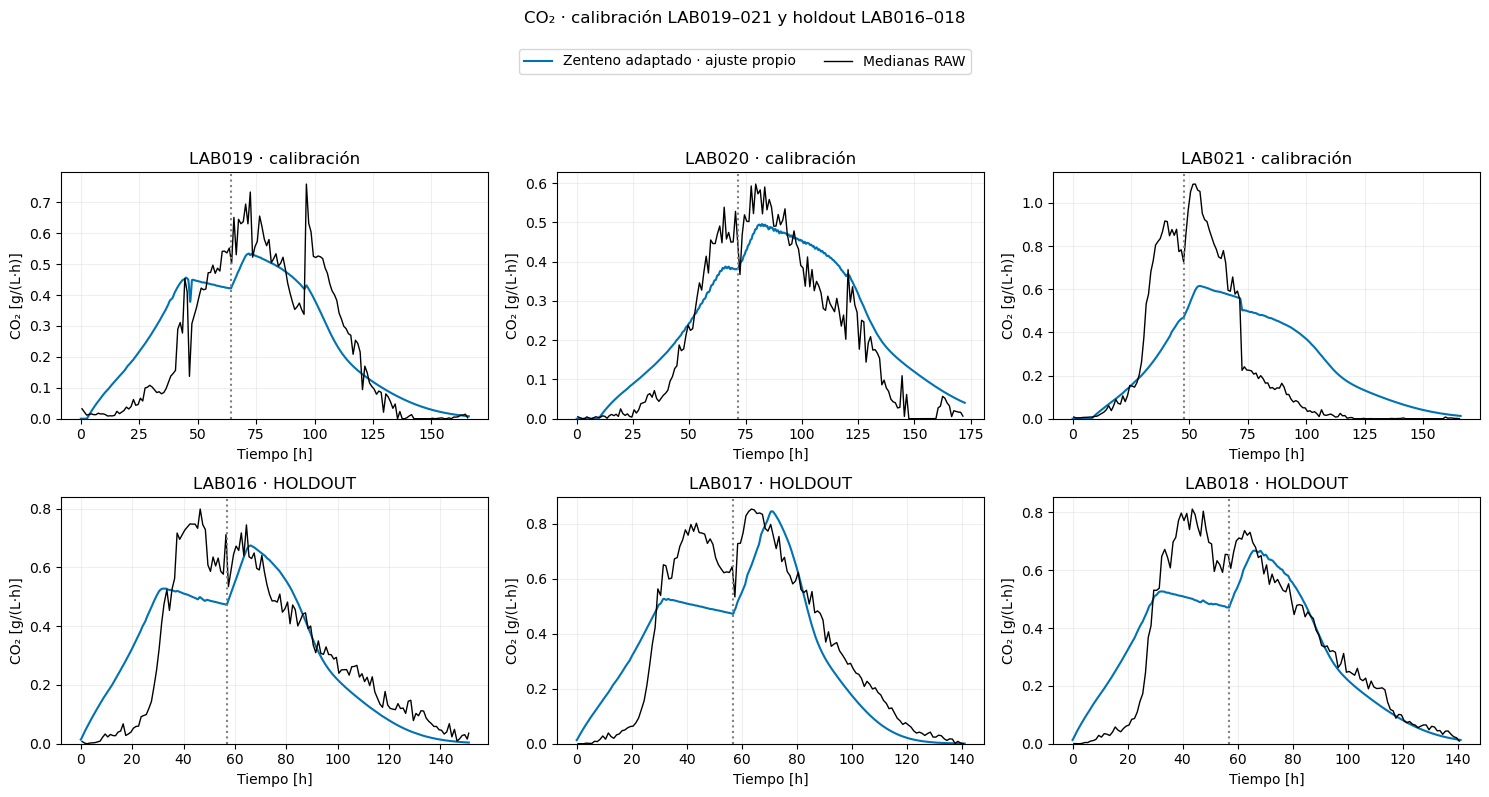

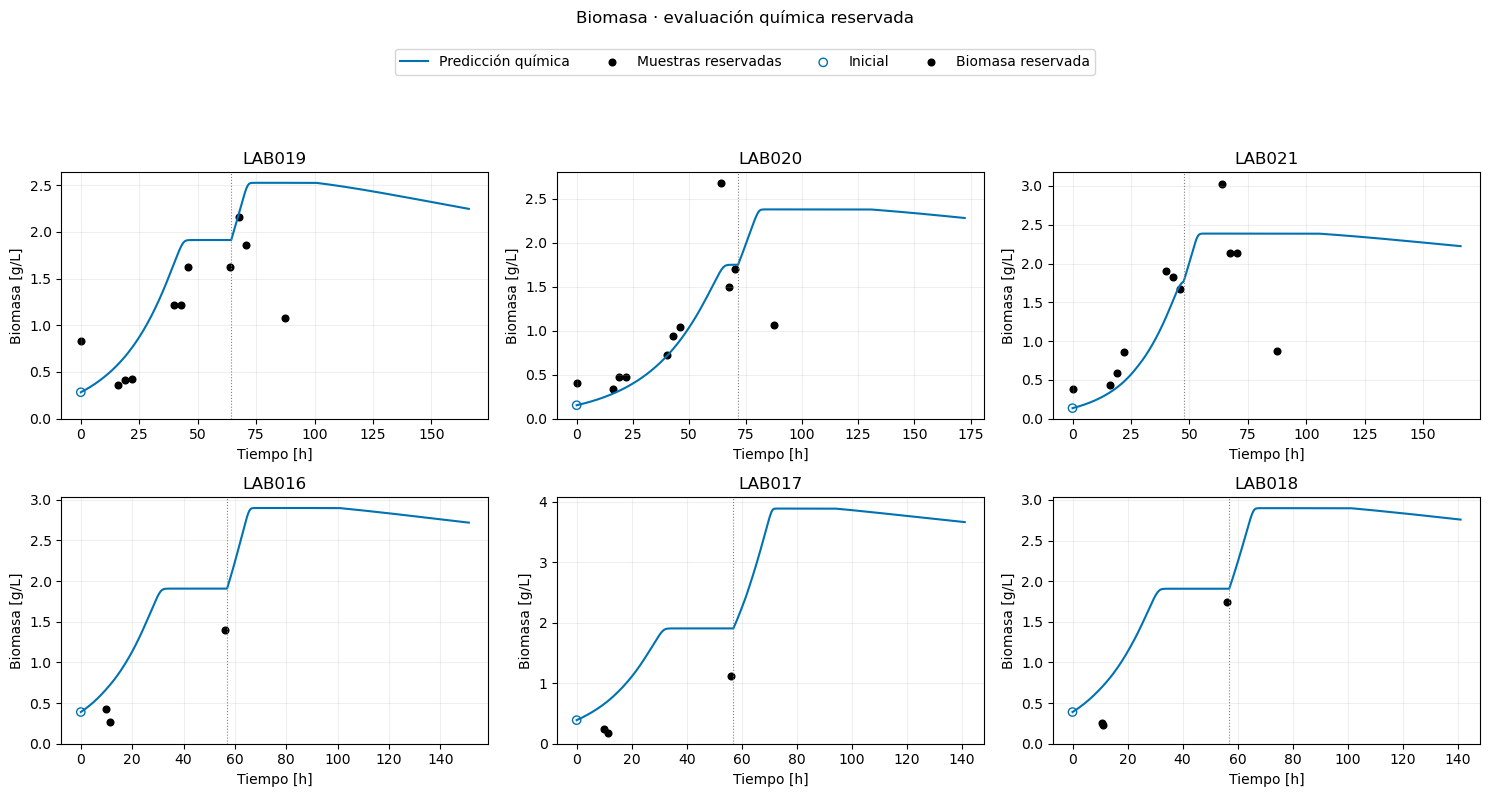

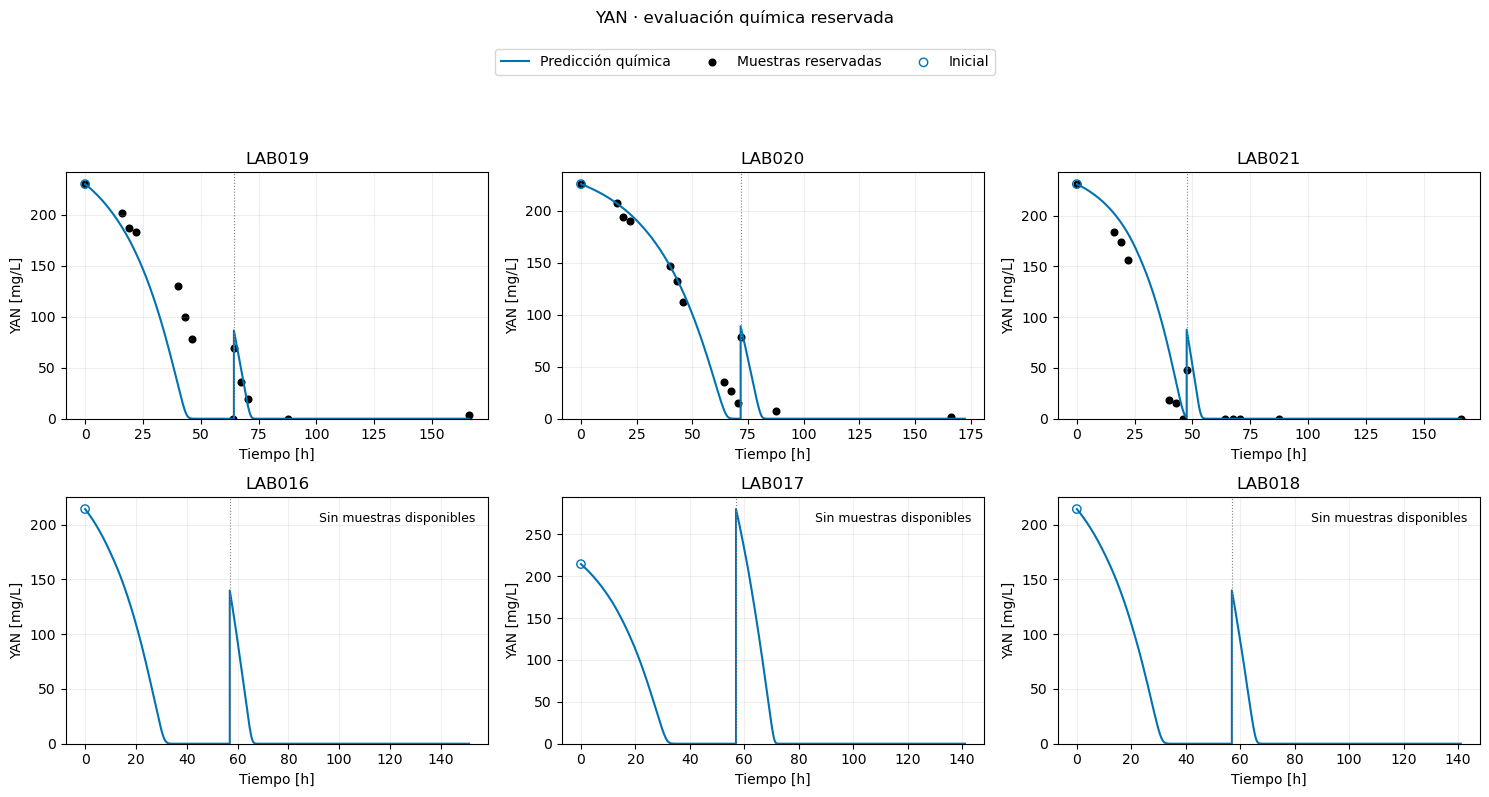

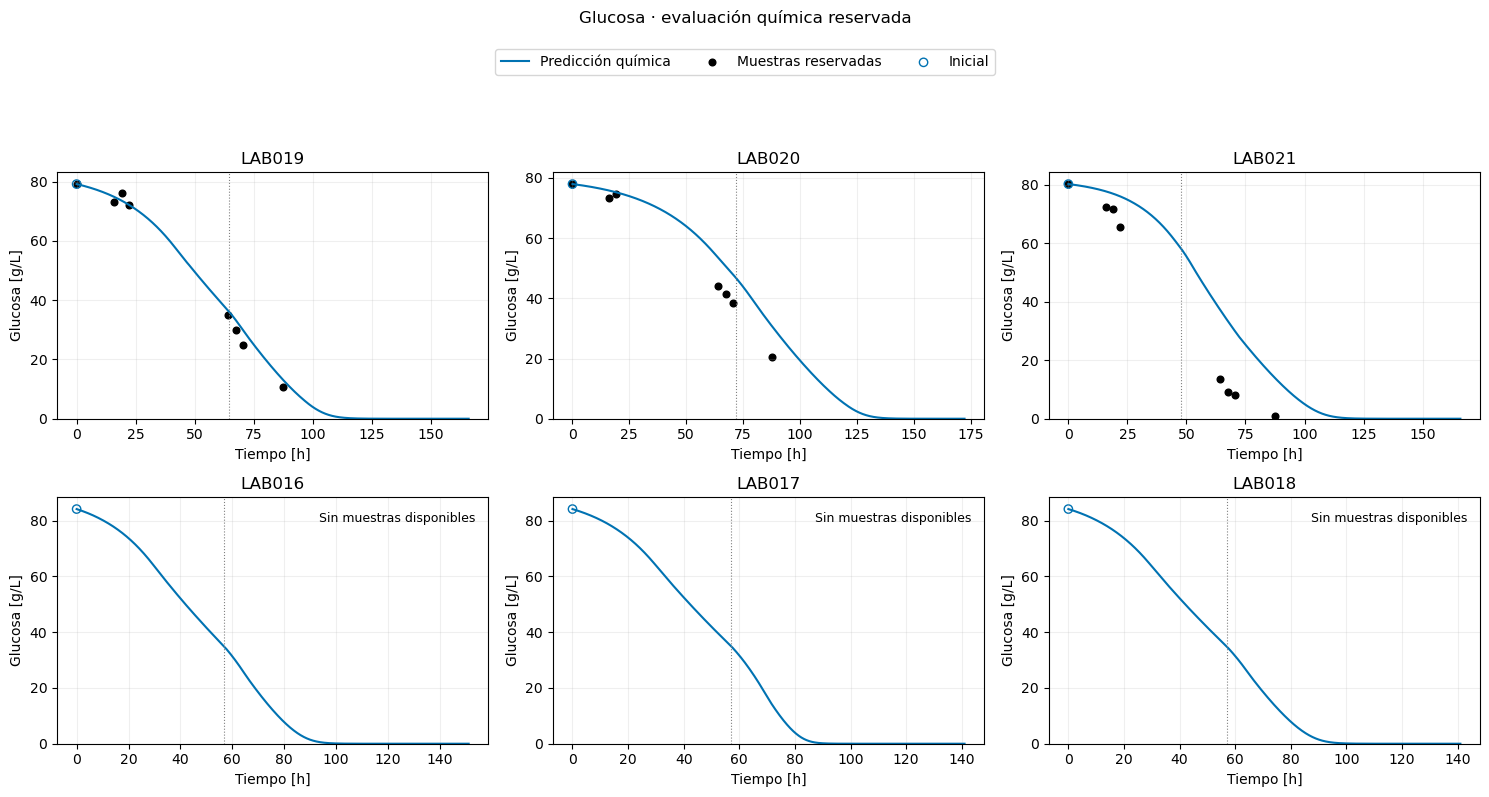

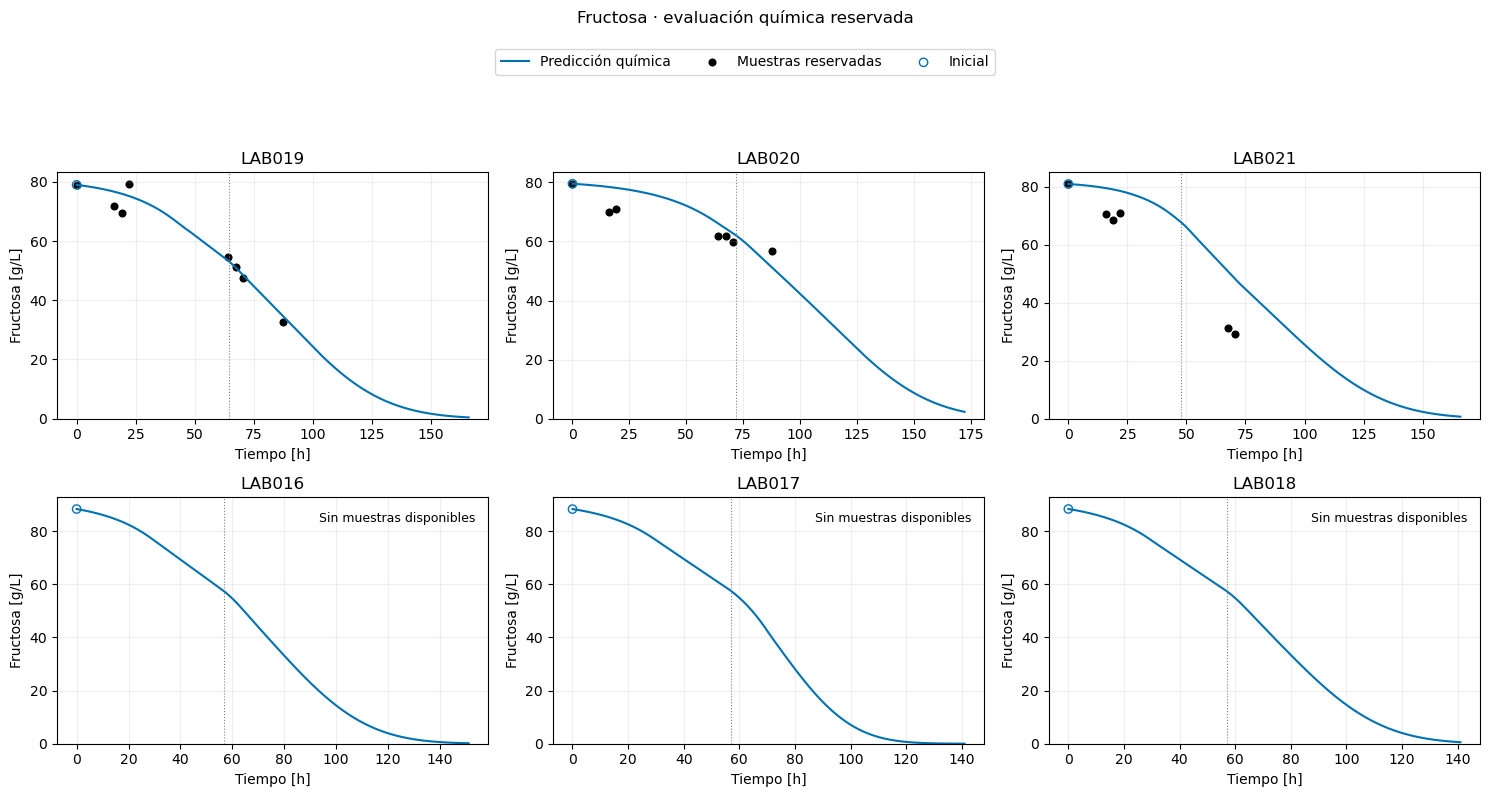

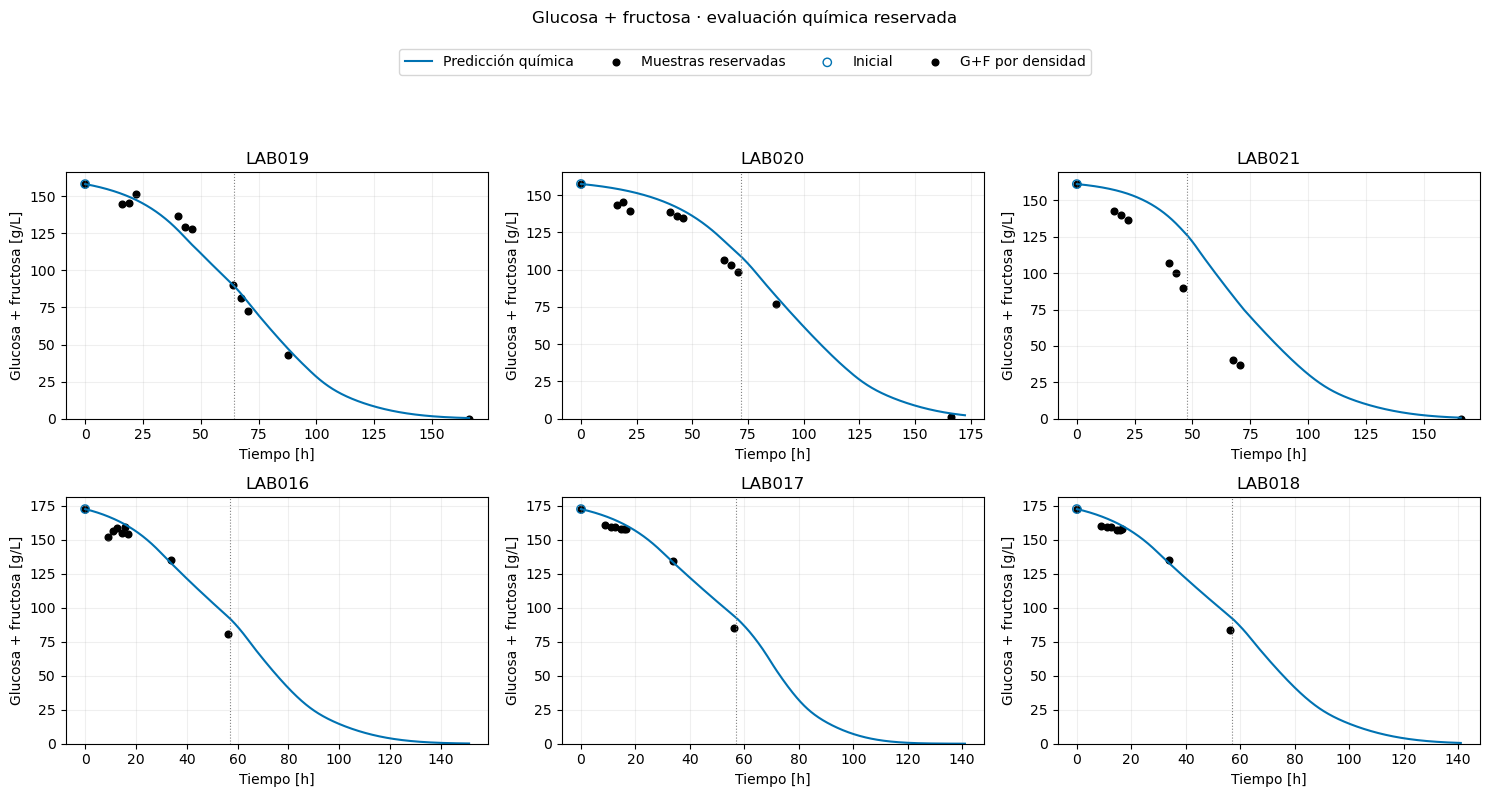

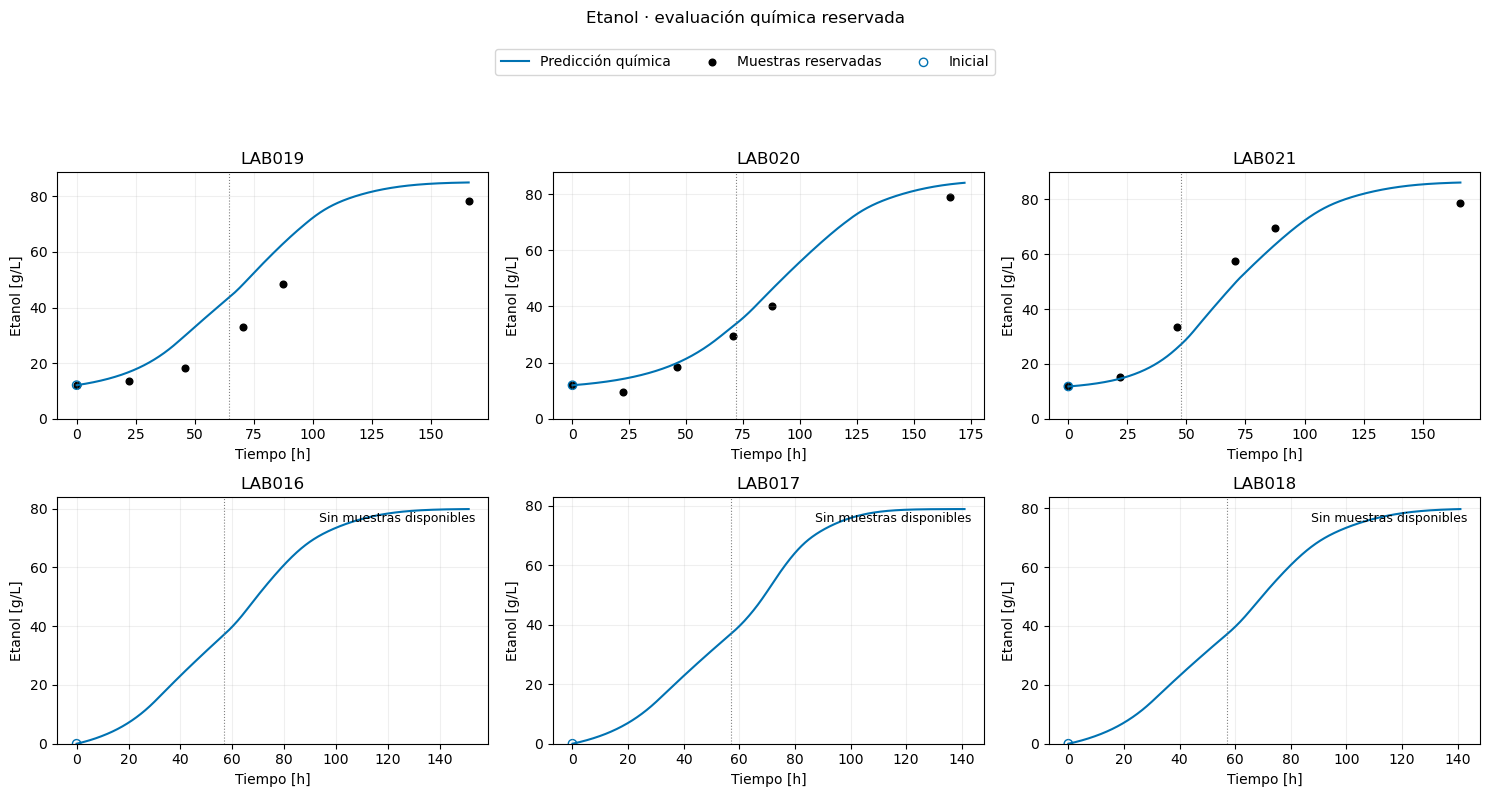

,LAB,variable,n,RMSE
0,LAB019,X,10,0.583969
1,LAB020,X,10,0.534696
2,LAB021,X,10,0.586712
3,LAB016,X,3,0.417242
4,LAB017,X,3,0.599355
5,LAB018,X,3,0.383953
6,LAB019,N,12,45.415569
7,LAB020,N,12,12.578998
8,LAB021,N,12,21.406950
9,LAB019,G,7,2.763706


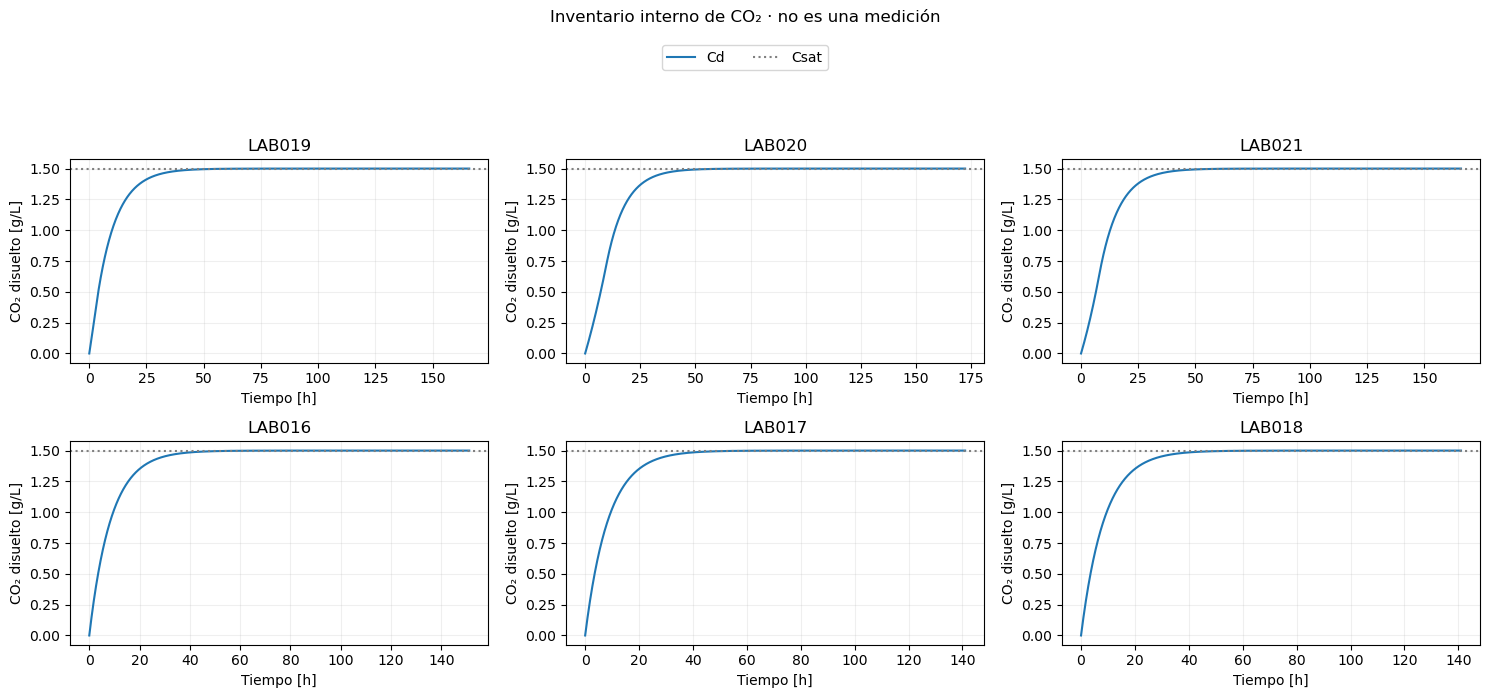

In [6]:
fig,axs=plt.subplots(2,3,figsize=(15,8))
for ax,lab in zip(axs.flat,LABS):
 f=curves[lab];m=f.index<=v.horizons[lab];o=obs[lab]
 ax.plot(f.index[m],f.qpred[m],label='Zenteno adaptado · ajuste propio',c='#0072B2');ax.plot(o.time_h,o.co2_raw_g_l_h,c='black',lw=1,label='Medianas RAW')
 for t,d in batches[lab].pulses['N']:ax.axvline(t,c='gray',ls=':')
 ax.set(title=lab+(' · calibración' if lab in TRAIN else ' · HOLDOUT'),xlabel='Tiempo [h]',ylabel='CO₂ [g/(L·h)]',ylim=(0,None));ax.grid(alpha=.2)
fig.suptitle('CO₂ · calibración LAB019–021 y holdout LAB016–018',y=.99);fig.legend(*axs.flat[0].get_legend_handles_labels(),loc='upper center',bbox_to_anchor=(.5,.95),ncol=2);fig.tight_layout(rect=(0,0,1,.87));plt.show()
chemmetrics=[]
for s,title,scale in [('X','Biomasa',1),('N','YAN',1000),('G','Glucosa',1),('F','Fructosa',1),('GF','Glucosa + fructosa',1),('E','Etanol',1)]:
 fig,axs=plt.subplots(2,3,figsize=(15,8));items={}
 for ax,lab in zip(axs.flat,LABS):
  f=with_jumps(cores[lab]);m=f.index<=v.horizons[lab];ax.plot(f.index[m],f[s][m]*scale,c='#0072B2',label='Predicción química')
  if lab in TRAIN:
   z=chemical_observations(v.chem,lab,s);tt=z.t_h.to_numpy();yy=z[CHEMICAL_COLUMNS[s]].to_numpy();label='Muestras reservadas'
  elif s=='X':
   z=v.biomass.loc[v.biomass.lab.eq(lab)].dropna(subset=['t_h','X_viable_g_l']);tt=z.t_h.to_numpy();yy=z.X_viable_g_l.to_numpy();label='Biomasa reservada'
  elif s=='GF':
   z=v.density.loc[v.density.lab.eq(lab)].dropna(subset=['t_h','density_g_l']);tt=z.t_h.to_numpy();yy=2.5*(z.density_g_l.to_numpy()-1000);label='G+F por densidad'
  else:tt=np.array([]);yy=np.array([]);label='Sin datos disponibles'
  if len(tt):ax.scatter(tt,yy*scale,c='black',s=23,label=label)
  else:ax.text(.97,.9,'Sin muestras disponibles',ha='right',transform=ax.transAxes,fontsize=9)
  score=(tt>0)&(tt<=v.horizons[lab])
  if score.any():
   e=(np.interp(tt[score],f.index,f[s])-yy[score])*scale;chemmetrics.append(dict(LAB=lab,variable=s,n=score.sum(),RMSE=np.sqrt(np.mean(e*e))))
  ax.scatter([0],[batches[lab].initials[s]*scale if s!='GF' else (batches[lab].initials['G']+batches[lab].initials['F'])*scale],facecolors='none',edgecolors='#0072B2',label='Inicial')
  for t,d in batches[lab].pulses['N']:ax.axvline(t,c='gray',ls=':',lw=.8)
  ax.set(title=lab,xlabel='Tiempo [h]',ylabel=title+(' [mg/L]' if s=='N' else ' [g/L]'),ylim=(0,None));ax.grid(alpha=.2)
  for h,l in zip(*ax.get_legend_handles_labels()):items[l]=h
 fig.suptitle(title+' · evaluación química reservada',y=.99);fig.legend(items.values(),items.keys(),loc='upper center',bbox_to_anchor=(.5,.95),ncol=4);fig.tight_layout(rect=(0,0,1,.87));plt.show()
display(pd.DataFrame(chemmetrics))
fig,axs=plt.subplots(2,3,figsize=(15,7))
for ax,lab in zip(axs.flat,LABS):
 f=curves[lab];m=f.index<=v.horizons[lab];ax.plot(f.index[m],f.Cd[m],label='Cd');ax.axhline(CSAT,c='gray',ls=':',label='Csat');ax.set(title=lab,xlabel='Tiempo [h]',ylabel='CO₂ disuelto [g/L]');ax.grid(alpha=.2)
fig.suptitle('Inventario interno de CO₂ · no es una medición',y=.99);fig.legend(*axs.flat[0].get_legend_handles_labels(),loc='upper center',bbox_to_anchor=(.5,.95),ncol=2);fig.tight_layout(rect=(0,0,1,.87));plt.show()


## Comprobaciones y lectura final
La química fue reajustada con muestras depuradas tratadas, sin datos de validación. El gas usa solamente019–021 y una ganancia nueva. La conservación comprobada corresponde al depósito físico antes de ganancia. Una retirada homogénea conserva Cd y retira masa disuelta; la tabla de masas explicita ese término. Kn, límites y errores químicos deben revisarse junto al gas: una mejora del sensor no demuestra estados correctos ni parámetros únicos.


In [7]:
display(pd.DataFrame([dict(LAB=lab,t_h=j['t'],dosis_g_L=j['dose'],N_pre_g_L=j['before'][1],N_post_g_L=j['after'][1]) for lab,f in {**traincurves,**cores}.items() for j in f.attrs['pulse_jumps']]))
display(pd.DataFrame([dict(LAB=lab,**f.attrs['minimum_integrated_states']) for lab,f in cores.items()]))
masschecks=[]
for lab in LABS:
 f=curves[lab];t=f.index.to_numpy();V=volumes[lab](t);dt=np.diff(t);q=f.qprod.to_numpy();cd=f.Cd.to_numpy();out=f.qgas.to_numpy()
 produced=np.sum(V[:-1]*dt*(q[:-1]+q[1:])/2);emitted=np.sum(V[:-1]*dt*out[1:]);removed=np.sum((V[:-1]-V[1:])*cd[1:]);err=V[-1]*cd[-1]-V[0]*cd[0]-produced+emitted+removed
 assert abs(err)<1e-8
 masschecks.append(dict(LAB=lab,produccion_g=produced,gas_g=emitted,retirado_disuelto_g=removed,final_disuelto_g=V[-1]*cd[-1],error_g=err))
display(pd.DataFrame(masschecks))
assert all(hashlib.sha256(p.read_bytes()).hexdigest()==h for p,h in hashes.items())
print('Archivos previos intactos; ninguna configuración ni dato sobrescrito.')
assert theta['Kd0']==KD0_ZENTENO_H and 'Kd0' not in names
assert theta['Kn0']==start['Kn0'] and 'Kn0' not in names
print('Kd0 fijo h^-1:',theta['Kd0'])
print('Kn a23C fijo:',theta['Kn0']*KN_THERMAL_FACTOR)
print('Kn0 final g/L:',theta['Kn0'],'sigmaX:',SIGMA_X,'kLa:',KLA,'ganancia:',GAIN)
print('Convergencia química seleccionada:',best.success,'; límites gas:',KLA,GAIN)
print('RMSE medio gas por rol:',metrics.groupby('rol').RMSE.mean().to_dict())


Archivos previos intactos; ninguna configuración ni dato sobrescrito.
Kd0 fijo h^-1: 0.00044
Kn a23C fijo: 0.01
Kn0 final g/L: 0.008257860224319971 sigmaX: 0.5 kLa: 0.11558424718334451 ganancia: 0.6204348696214814
Convergencia química seleccionada: True ; límites gas: 0.11558424718334451 0.6204348696214814
RMSE medio gas por rol: {'Calibración gas': 0.14427689472670688, 'Holdout gas': 0.13597464716801835}


,LAB,t_h,dosis_g_L,N_pre_g_L,N_post_g_L
0,LAB004,68.500000,0.080000,-4.274481e-12,0.080000
1,LAB005,68.500000,0.080000,7.835249e-37,0.080000
2,LAB006,100.000000,0.080000,3.517937e-21,0.080000
3,LAB007,65.500000,0.080000,-4.356345e-12,0.080000
4,LAB008,65.500000,0.080000,9.981826e-17,0.080000
5,LAB009,41.846154,0.080000,3.340483e-10,0.080000
6,LAB019,64.333333,0.086486,1.965833e-18,0.086486
7,LAB020,71.666667,0.088889,3.351478e-07,0.088889
8,LAB021,47.500000,0.086486,1.180297e-03,0.087667
9,LAB016,56.935556,0.140000,1.578969e-22,0.140000


,LAB,X,N,G,F,E
0,LAB019,0.284239,-1.025740e-11,2.281936e-08,0.089535,12.085919
1,LAB020,0.153835,-3.474697e-72,3.358718e-06,1.043165,11.922922
2,LAB021,0.136815,-2.184072e-13,3.790078e-08,0.155204,11.765200
3,LAB016,0.391762,-1.901577e-13,2.601801e-08,0.173710,0.017049
4,LAB017,0.391710,-1.670839e-11,1.908898e-12,0.004008,0.016912
5,LAB018,0.391712,-1.085013e-31,2.705081e-08,0.179379,0.016918


,LAB,produccion_g,gas_g,retirado_disuelto_g,final_disuelto_g,error_g
0,LAB019,127.325476,124.407080,0.368396,2.55,3.996803e-14
1,LAB020,124.403773,121.488720,0.365052,2.55,1.620926e-14
2,LAB021,129.732348,126.816420,0.365929,2.55,3.036460e-14
3,LAB016,152.415058,149.415058,0.000000,3.00,2.842171e-14
4,LAB017,150.935839,147.935839,0.000000,3.00,0.000000e+00
5,LAB018,152.425443,149.425443,0.000000,3.00,0.000000e+00
